# Adaptive-threshold and STDP-pretrained SNNs: 2,250 m / 120 s

Three new variants, each trained for **60 Expected SARSA episodes across three seeds**:

- **Adaptive reservoir:** same signed random hidden weights as the old reservoir;
  spike-triggered thresholds adapt within each observation, starting from zero.
- **Prototype control (no STDP):** positive normalized hidden weights, inhibitory
  feedback, and threshold calibration using training observations. Hidden weights stay fixed.
- **STDP-pretrained prototypes:** identical initialization, inhibition, data order,
  and calibration protocol as the prototype control, with weight-dependent pair STDP.

Prototype variants carry adaptive thresholds across pretraining observations. Then
both hidden weights and thresholds freeze while Expected SARSA trains the signed
linear readout. Membranes reset each observation. Inference and target evaluation
never mutate persistent state. The adaptive reservoir instead continues local
within-window adaptation during both learning and evaluation.

This is a **Diehl–Cook-inspired current-based LIF experiment**, not a full reproduction:
no conductance dynamics, biological time calibration, refractory period, or exact
original plasticity rule. Inhibition is aggregate feedback from the previous
internal step. STDP here is unsupervised, not reward-modulated. Q learning still
uses the detached Expected SARSA target and Adam on the readout.

Reference: [Diehl & Cook (2015)](https://www.frontiersin.org/journals/computational-neuroscience/articles/10.3389/fncom.2015.00099/full).

Run All reviews the archived results. Train the base SNN study first to run a fresh matched comparison.

In [1]:
from pathlib import Path
import os, sys, json, time, subprocess, hashlib
from concurrent.futures import ThreadPoolExecutor, wait, FIRST_COMPLETED
os.environ.setdefault("MPLBACKEND", "Agg")
os.environ.setdefault("SDL_AUDIODRIVER", "dummy")
os.environ.setdefault("PYGAME_HIDE_SUPPORT_PROMPT", "1")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "experiments/adaptive_snn_study.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from experiments.adaptive_snn_study import (initialize, summarize, OUTPUT, CONTROL, SEEDS,
    VARIANTS, PRETRAIN_EPISODES, PRETRAIN_PASSES)
from algorithms.snn import AdaptiveSNNSettings
from environments.sensor_highway import ExperimentConfig
RUN_TRAINING = False  # Set True after running the base SNN notebook with training on.
RECORDED = ROOT / "runs/exploratory/adaptive_snn_120s_60ep_3seeds_v1"
if RUN_TRAINING:
    config, settings = initialize()
else:
    config = ExperimentConfig.load(RECORDED / "config.json")
    settings = AdaptiveSNNSettings(episodes=60)
    OUTPUT = ROOT / "runs/local/adaptive_snn_review"
    OUTPUT.mkdir(parents=True, exist_ok=True)
    source = RECORDED
print("Interpreter:", sys.executable)
print("Task:", config.reward.route_distance_m, "m /", config.highway["duration"], "s")
print("Outputs:", OUTPUT)
display(pd.Series(vars(settings), name="Adaptive SNN settings"))

Interpreter: /Users/zac/Desktop/Reinforcment_Learning/final_project/.venv/bin/python
Task: 2250 m / 120 s
Outputs: /Users/zac/Desktop/Reinforcment_Learning/final_project/experiments/artifacts/adaptive_snn_120s_60ep_3seeds_v1


episodes                   60.000
learning_rate               0.001
gamma                       0.950
epsilon_start               1.000
epsilon_end                 0.100
hidden_size                64.000
simulation_steps           16.000
membrane_decay              0.900
threshold                   1.000
surrogate_slope             5.000
gradient_clip              10.000
stdp_learning_rate          0.001
trace_decay                 0.800
stdp_depression             1.050
td_modulation_clip          5.000
weight_bound                1.000
threshold_decay             0.950
threshold_increment         0.100
prototype_weight_sum        4.000
prototype_weight_max        0.250
prototype_learning_rate     0.002
inhibition                  0.100
Name: Adaptive SNN settings, dtype: float64

## Protocol and controls

Readout training matches the earlier study: randomized weather, 20 joint actions,
gamma 0.95, epsilon 1.0 → 0.1, and training seeds 42, 1042, 2042. Each model is tested
on traffic seeds 100000–100003 in clear, rain, and fog: **12 test trips per model**.
No test observations or rewards are used for pretraining or parameter selection.

Each seed's prototype corpus comes from **20 additional random-policy episodes**
on the same 120-second task, with seeds `training_seed + 10000 + episode`.
Both prototype variants see this same corpus over three identically shuffled passes.
Only observation features enter pretraining. Their Q readouts are zero until
Expected SARSA training starts. Repeated passes do not add environment interactions.

Archived linear and fixed-threshold reservoir evaluations are imported after
checking task/settings, package versions, and legacy implementation source hashes.
The new adaptive classes are appended to `snn.py`; the old implementation is unchanged.

New work: **540 readout-training episodes, 60 corpus-collection episodes, and
108 evaluation trips**. The final table also includes **72 archived control trips**.
Prototype methods have an extra data budget; compare them directly with their
matched prototype control to assess STDP. Concurrent CPU workers make wall time
unsuitable for a controlled speed comparison. Three training seeds are exploratory.

In [2]:
if not RUN_TRAINING:
    summary = pd.read_csv(source / "summary.csv", index_col=0)
    per_seed = pd.read_csv(source / "per_training_seed.csv", index_col=[0, 1])
    evaluation = pd.read_csv(source / "evaluation.csv")
    print("Loaded recorded results:", source.relative_to(ROOT))
else:
    # Separate Python processes provide independent random streams and single-threaded Torch.
    # Each seed writes only its own directory; finished model evaluations are reusable on rerun.
    def launch_seed(seed):
        log_path = OUTPUT / f"seed{seed}.log"
        with log_path.open("a", buffering=1) as log:
            result = subprocess.run([sys.executable, "-m", "experiments.adaptive_snn_study", "--seed", str(seed)],
                                    cwd=ROOT, stdout=log, stderr=subprocess.STDOUT)
        if result.returncode:
            raise RuntimeError(f"Seed {seed} failed; see {log_path}")
        return seed
    with ThreadPoolExecutor(max_workers=3) as pool:
        pending = {pool.submit(launch_seed, seed): seed for seed in SEEDS}
        while pending:
            done, _ = wait(pending, timeout=30, return_when=FIRST_COMPLETED)
            for future in done:
                print("Completed training seed", future.result(), flush=True)
                del pending[future]
            for seed in pending.values():
                log = OUTPUT / f"seed{seed}.log"
                if log.exists() and log.read_text().splitlines():
                    print(f"Seed {seed}: {log.read_text().splitlines()[-1]}", flush=True)
    summary, per_seed, evaluation = summarize()
    assert len(evaluation) == 180
    assert (evaluation.elapsed_s <= 120 + 1e-8).all()
    assert len(pd.read_csv(OUTPUT / "training.csv")) == 540
    print("All new models and evaluations completed.")
    source = OUTPUT

Seed 42: adaptive_reservoir seed 42: 10/60; return=-19.30; wall=9.0s


Seed 1042: adaptive_reservoir seed 1042: 10/60; return=-18.87; wall=7.5s


Seed 42: adaptive_reservoir seed 42: 20/60; return=-18.32; wall=27.9s


Seed 1042: adaptive_reservoir seed 1042: 40/60; return=-13.59; wall=33.7s


Seed 2042: adaptive_reservoir seed 2042: 30/60; return=-19.13; wall=23.3s


Seed 42: adaptive_reservoir seed 42: 50/60; return=-19.28; wall=62.4s


... (70 outputs left out)

Completed training seed 2042


Seed 42: Evaluated rain


Completed training seed 42


All new models and evaluations completed.


## Held-out results

Aggregate the 12 test trips per trained model first, then average across the three
training seeds. SD describes variation across trained models, not a confidence
interval. Completion and crashes must accompany sensor energy: early crashes can
reduce trip energy. Sensor energy excludes neural computation.

The previous fixed-threshold reservoir versus adaptive reservoir comparison
isolates within-window threshold adaptation. Prototype control versus STDP
pretraining compares hidden synaptic learning with matched extra observations,
initialization, and threshold calibration. It includes any downstream effect of
STDP on the calibrated thresholds.

,completion_mean,completion_sd,crash_mean,return_mean,sensor_power_w
policy,,,,,
Adaptive reservoir,1.000,0.000,0.000,31.889,9.120
Linear Expected SARSA,0.667,0.577,0.333,16.158,1.800
Prototype control (no STDP),1.000,0.000,0.000,24.857,73.564
SNN fixed reservoir,0.444,0.509,0.556,3.565,66.531
STDP-pretrained prototypes,1.000,0.000,0.000,28.116,43.536


completion  crash  mean_return  \
policy                      training_seed                                   
Adaptive reservoir          42                  1.000  0.000       30.446   
                            1042                1.000  0.000       32.610   
                            2042                1.000  0.000       32.610   
Linear Expected SARSA       42                  0.000  1.000      -16.745   
                            1042                1.000  0.000       32.610   
                            2042                1.000  0.000       32.610   
Prototype control (no STDP) 42                  1.000  0.000       30.562   
                            1042                1.000  0.000       24.669   
                            2042                1.000  0.000       19.341   
SNN fixed reservoir         42                  1.000  0.000       30.082   
                            1042                0.000  1.000      -18.026   
                            2042                0.333  0.667       -1.361   
STDP-pretrained prototypes  42                  1.000  0.000       30.592   
                            1042                1.000  0.000       21.147   
                            2042                1.000  0.000       32.610   

                                           sensor_power_w  successful_time_s  
policy                      training_seed                                     
Adaptive reservoir          42                     23.761             112.50  
                            1042                    1.800             112.50  
                            2042                    1.800             112.50  
Linear Expected SARSA       42                      1.800                NaN  
                            1042                    1.800             112.50  
                            2042                    1.800             112.50  
Prototype control (no STDP) 42                     22.791             112.50  
                            1042                   74.900             112.50  
                            2042                  123.000             112.50  
SNN fixed reservoir         42                     27.198             112.25  
                            1042                  121.804                NaN  
                            2042                   50.592             106.50  
STDP-pretrained prototypes  42                     22.500             112.50  
                            1042                  106.308             112.50  
                            2042                    1.800             112.50

completion  crash  power_w
policy                      weather                            
Adaptive reservoir          clear         1.000  0.000    9.185
                            fog           1.000  0.000    9.030
                            rain          1.000  0.000    9.146
Linear Expected SARSA       clear         0.667  0.333    1.800
                            fog           0.667  0.333    1.800
                            rain          0.667  0.333    1.800
Prototype control (no STDP) clear         1.000  0.000   73.622
                            fog           1.000  0.000   73.583
                            rain          1.000  0.000   73.486
SNN fixed reservoir         clear         0.333  0.667   68.879
                            fog           0.583  0.417   62.977
                            rain          0.417  0.583   67.737
STDP-pretrained prototypes  clear         1.000  0.000   41.636
                            fog           1.000  0.000   45.270
                            rain          1.000  0.000   43.702

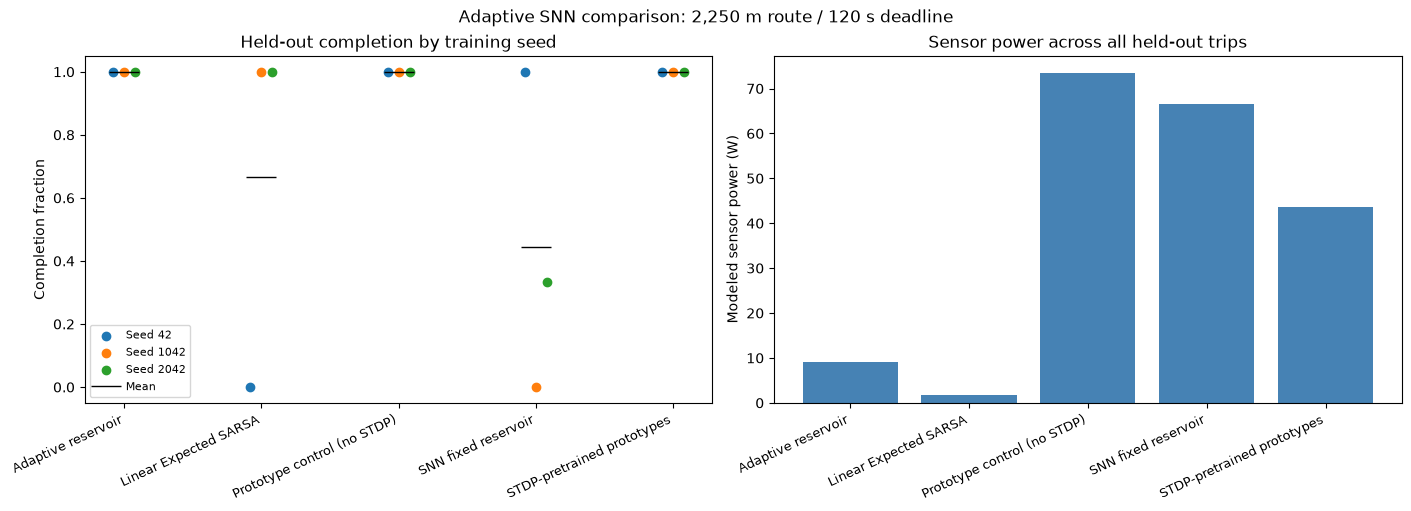

In [3]:
display(summary.round(3))
display(per_seed.round(3))
weather = evaluation.groupby(["policy", "weather"]).agg(
    completion=("completed", "mean"), crash=("crashed", "mean"), power_w=("mean_power_w", "mean"))
weather.to_csv(OUTPUT / "weather_summary.csv")
display(weather.round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
labels = list(summary.index)
x = np.arange(len(labels))
for i, seed in enumerate(SEEDS):
    points = per_seed.xs(seed, level="training_seed").reindex(labels)
    axes[0].scatter(x+(i-1)*.08, points.completion, label=f"Seed {seed}")
axes[0].plot(x, summary.completion_mean, "k_", markersize=22, label="Mean")
axes[0].set(ylabel="Completion fraction", ylim=(-.05, 1.05), title="Held-out completion by training seed")
axes[0].legend(fontsize=8)
axes[1].bar(x, summary.sensor_power_w, color="steelblue")
axes[1].set(ylabel="Modeled sensor power (W)", title="Sensor power across all held-out trips")
for ax in axes:
    ax.set_xticks(x, labels, rotation=25, ha="right", fontsize=9)
fig.suptitle("Adaptive SNN comparison: 2,250 m route / 120 s deadline")
fig.savefig(OUTPUT / "comparison.png", dpi=160)
display(fig)
plt.close(fig)

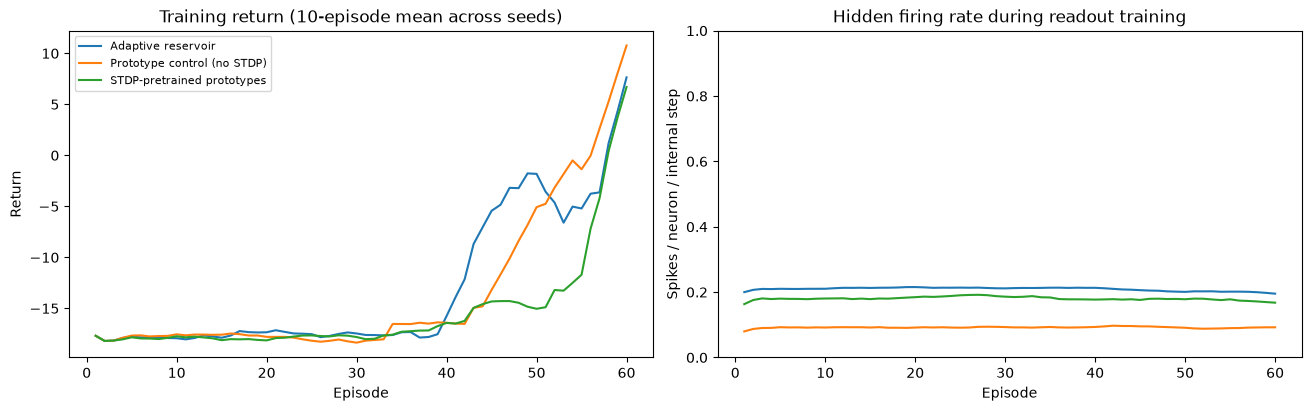

,policy,training_seed,hidden_weight_l2_change,threshold_offset_mean,pretraining_observations
0,Adaptive reservoir,42,0.0000,0.0000,0.0
1,Prototype control (no STDP),42,0.0000,0.2213,1101.0
2,STDP-pretrained prototypes,42,2.2861,0.4659,1101.0
3,Adaptive reservoir,1042,0.0000,0.0000,0.0
4,Prototype control (no STDP),1042,0.0000,0.1888,987.0
5,STDP-pretrained prototypes,1042,2.1360,0.4015,987.0
6,Adaptive reservoir,2042,0.0000,0.0000,0.0
7,Prototype control (no STDP),2042,0.0000,0.1963,1737.0
8,STDP-pretrained prototypes,2042,2.6288,0.4133,1737.0


,pass,observations,hidden_spike_rate,silent_hidden_fraction,mean_threshold_offset,mean_abs_eligibility,policy,training_seed
0,1,367,0.0955,0.0727,0.1832,0.0000,Prototype control (no STDP),42
1,2,367,0.0950,0.0777,0.1823,0.0000,Prototype control (no STDP),42
2,3,367,0.0955,0.0757,0.1840,0.0000,Prototype control (no STDP),42
3,1,367,0.1195,0.1068,0.2310,0.0069,STDP-pretrained prototypes,42
4,2,367,0.1591,0.1381,0.3113,0.0079,STDP-pretrained prototypes,42
5,3,367,0.1815,0.1517,0.3563,0.0082,STDP-pretrained prototypes,42
6,1,329,0.0917,0.0742,0.1764,0.0000,Prototype control (no STDP),1042
7,2,329,0.0908,0.0786,0.1746,0.0000,Prototype control (no STDP),1042
8,3,329,0.0920,0.0771,0.1779,0.0000,Prototype control (no STDP),1042
9,1,329,0.1092,0.1158,0.2092,0.0061,STDP-pretrained prototypes,1042


Representation checks passed: hidden weights changed only under STDP pretraining.


In [4]:
training = pd.read_csv(source / "training.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for label, group in training.groupby("policy"):
    curves = group.pivot(index="episode", columns="training_seed", values="return").rolling(10, min_periods=1).mean()
    axes[0].plot(curves.index, curves.mean(axis=1), label=label)
    rates = group.groupby("episode").hidden_spike_rate.mean().rolling(10, min_periods=1).mean()
    axes[1].plot(rates.index, rates, label=label)
axes[0].set(title="Training return (10-episode mean across seeds)", xlabel="Episode", ylabel="Return")
axes[1].set(title="Hidden firing rate during readout training", xlabel="Episode", ylabel="Spikes / neuron / internal step", ylim=(0,1))
axes[0].legend(fontsize=8)
fig.savefig(OUTPUT / "training_activity.png", dpi=160)
display(fig)
plt.close(fig)
representation = []
pretraining = []
for seed in SEEDS:
    for variant, label in VARIANTS.items():
        folder = source / f"seed{seed}" / variant
        row = pd.read_csv(folder / "representation.csv", index_col=0).iloc[:,0].to_dict()
        representation.append({"policy": label, "training_seed": seed, **row})
        if (folder / "pretraining.csv").exists():
            pretraining.append(pd.read_csv(folder / "pretraining.csv").assign(policy=label, training_seed=seed))
representation = pd.DataFrame(representation)
representation.to_csv(OUTPUT / "representations.csv", index=False)
display(representation.round(4))
if pretraining:
    pretraining = pd.concat(pretraining, ignore_index=True)
    pretraining.to_csv(OUTPUT / "pretraining_diagnostics.csv", index=False)
    display(pretraining.round(4))
for label in ["Adaptive reservoir", "Prototype control (no STDP)"]:
    assert (representation.loc[representation.policy == label, "hidden_weight_l2_change"] == 0).all()
assert (representation.loc[representation.policy == "STDP-pretrained prototypes", "hidden_weight_l2_change"] > 0).all()
print("Representation checks passed: hidden weights changed only under STDP pretraining.")

In [5]:
counts = evaluation.groupby("policy").completed.agg(["sum", "count"])
lines = ["# Adaptive SNN experiments: 2,250 m / 120 s", "",
         "New experiments: three variants × three training seeds × 60 readout episodes = 540 episodes.",
         "Pretraining corpus: 20 extra random-policy episodes per seed, reused by both prototype variants over three passes.",
         "108 new held-out trips; 72 archived control trips. No test data used for training.", "",
         "| Policy | Completed | Completion | Crash | Mean return | Sensor power (W) |",
         "|---|---:|---:|---:|---:|---:|"]
for label, row in summary.iterrows():
    lines.append(f"| {label} | {int(counts.loc[label,'sum'])}/{int(counts.loc[label,'count'])} | {row.completion_mean:.1%} | {row.crash_mean:.1%} | {row.return_mean:.2f} | {row.sensor_power_w:.2f} |")
lines += ["", "## Interpretation and limits", "",
          "Diehl-Cook-inspired adaptive current-based LIF, not a full reproduction of the original conductance-based network.",
          "STDP is unsupervised pretraining; Expected SARSA still trains an analog Q readout using Adam semi-gradients.",
          "Prototype weights and calibrated thresholds freeze before Q learning. Adaptive reservoir thresholds reset and adapt within each observation.",
          "No persistent state is modified by target evaluation or action selection.",
          "Compare STDP with the matched prototype control; prototype methods have extra data relative to the reservoirs.",
          "Three training seeds and 60 readout episodes do not establish convergence or an overall best architecture.",
          "Sensor power excludes neural computation; concurrent wall times are not speed benchmarks.", "",
          "Full per-seed data, corpus arrays, diagnostics, checkpoints, source hashes, and plots are saved alongside this report."]
(OUTPUT / "study_report.md").write_text("\n".join(lines)+"\n")
metadata = json.loads((source / "metadata.json").read_text())
metadata.update(status="complete", new_training_episodes=540, corpus_episodes=60,
                new_evaluation_trips=108, reused_evaluation_trips=72)
if RUN_TRAINING:
    (OUTPUT / "metadata.json").write_text(json.dumps(metadata, indent=2)+"\n")
print("Completed study:", OUTPUT)
print("Report:", OUTPUT / "study_report.md")

Completed study: /Users/zac/Desktop/Reinforcment_Learning/final_project/experiments/artifacts/adaptive_snn_120s_60ep_3seeds_v1
Report: /Users/zac/Desktop/Reinforcment_Learning/final_project/experiments/artifacts/adaptive_snn_120s_60ep_3seeds_v1/study_report.md


## Findings from this run

All three new variants completed **36/36 held-out trips**. The archived fixed-threshold reservoir completed 16/36; linear SARSA completed 24/36. The adaptive reservoir used 9.12 W of modeled sensor power on average. STDP-pretrained prototypes used 43.54 W versus 73.56 W for the matched no-STDP prototype control, with equal observed completion.

These results do not show a completion advantage from STDP over its prototype control. They support further testing of adaptive thresholds. Inspect `action_sensing_fractions.csv`: the adaptive reservoir selected SLOWER on every evaluated decision (the minimum target speed is 20 m/s), and left sensors off on two-thirds of decisions. Its success therefore reflects a conservative policy in these scenarios, not evidence of sophisticated perception. Sensor power excludes neural computation. Larger held-out traffic sets and more training seeds are needed to assess robustness.


## Replay an adaptive-reservoir policy

From the repository root, run `python -m experiments.replay_adaptive_snn`. The runner loads archived weights, verifies the trajectory against the saved trial, and exports a local replay.